<div style="text-align: right">INFO 7375 Systems Design, Midterm</div>
<div style="text-align: right">Dino Konstantopoulos, 27 October 2026</div>

# Midterm Break Scenario
<img src="ipynb.images/sd-eras.webp" width=1000/>
<br />

## Dino's initial thoughts about another Break Scenario for Week 5
Week 5's Scenario C ("consumer lag") is about artificially slowing one consumer down - inject latency into `InventoryConsumer`'s code, watch its queue back up. The lesson was "*queue depth is your instrument for a struggling consumer*".

Then I thought about another Break scenario: throw *real volume* at a real, unmodified system and see where it actually gives way. That's a genuine capacity/ceiling question, not a fault-injection question - and it connects directly to something we will revisit in Week 11, when we handle industry-proven modern transaction designs for robust systems.

As you saw in Week 4, `OrderService`s with fixed connection pools hit a hard resource ceiling under load and behave in a way that degrades gradually (rising latency, then collapse) until we fix the pool sizing. Week 6 also hits a resource ceiling, as you will see with a 100 requests/s load test. But Week 5's architecture is fundamentally different in kind: Lambda is *elastic*, DynamoDB is *on-demand*, SQS buffers *indefinitely*. <mark>Week5 hit no resource ceiling with our 100 requests /s load test. Week 5 flew through with flying colors</mark>. But the real, interesting design question is whether "*elastic*" means "*doesn't break at all*" or does it mean "*breaks differently*"? 

When i thought about this, my honest expectation - a hypothesis, not something I can assert with confidence - is that it breaks differently, in at least two specific ways:

**Lambda concurrency throttling**, not queueing collapse. Both `OrderProducer` (behind API Gateway) and each consumer have an account-level concurrent-execution ceiling. Push hard enough (instead of Week 11's gradually-rising latency we'll experience), you likely see a harder, more binary failure: `429 TooManyRequestsException` responses once we hit that ceiling, rather than everything just getting slower.

**A visible ramp-up lag in the SQS-to-Lambda scaling**, even though nothing is actually broken. AWS's SQS Event Source Mapping doesn't spin up maximum concurrency instantly - it scales polling concurrency up at a documented, gradual rate. A genuine burst of volume should produce a temporary queue-depth spike on the dashboard - not because anything failed, but because scaling itself takes time (for AWS to parry). I'll tell you right now, our Week 11 lesson learned will be: <mark>"elastic" doesn't mean "instant"</mark>, and a real-looking failure signal (rising queue depth) can just mean <mark>"still catching up", not "broken"</mark>.

### Cost and quotas
A genuine high-volume burst against real Lambda + DynamoDB + SNS + SQS + Kinesis will generate real (if modest, at course-lab scale) billed usage. Worth knowing roughly what volume we're comfortable with.

AWS account-level quotas - my account's default Lambda concurrency limit matters a lot here. A fresh/lightly-used AWS account might have a lower default ceiling than a heavily-used one, which would change what "breaks first".

We'd need roughly 270,000 ticket orders to spend $5 on AWS. Even a genuinely aggressive burst, 50,000 orders, costs under a dollar. 

Look at your account's real, current limits matter more than generic AWS defaults:

```bash
aws service-quotas get-service-quota --service-code lambda --quota-code L-B99A9384 \
  --query "Quota.Value" --output text   # concurrent executions limit, account-wide
```

We can design an arrival-rate ramp, not a flat rate - start modest, climb toward a few hundred/sec over a minute or two - specifically to find the point where something starts throttling, rather than guessing a single target number blind.

We need to set a hard, simple safety net - not cost-based given the math above, but a fixed test duration (e.g., cap it at 2 minutes regardless of what's happening), so a runaway Artillery config can't accidentally run far longer than intended.

My account quota says 1000 concurrent executions account-wide, the standard AWS default. That's a real, usable number for planning our load burst. Unfortunately, the TAs tell me that your account quota may be a lot lower. That is a problem. But we'll work with that. As a result of that, you may experience more errors, but you can still work on the designs and we'll take your quota in consideration.

## Taylor Swift's Concert ticket stampede

As you know from what I keep telling you, the Break scenarios we've been studying in class *happen all the time*. We need designs that do not break.

What actually happened to [Ticketmaster on November 15, 2022](https://people.com/music/taylor-swift-eras-tour-ticketmaster-timeline/), when its website collapsed under historically unprecedented traffic during the "Verified Fan" presale for Taylor Swift’s The Eras Tour, is a known, scheduled moment when a massive number of concurrent purchase attempts all arrive in the same narrow window. 

That's exactly what an Artillery ramp simulates — not gradual organic growth, a coordinated burst at a specific starting instant.

[Ticketmaster's Verified Fan system](https://time.com/6233959/ticketmaster-taylor-swift-verified-fan/), a registration platform designed to block scalper bots and prioritize real fans during high-demand concert and event presales, was built and provisioned around 1.5 million fans who had been given presale access - a real, deliberate capacity plan. 

What actually showed up for the ticket selling event was 14 million users, including bots, *all at once*. That's not a modest overrun - it was roughly 9-10x the planned volume, hitting a single scheduled instant rather than spreading out. 

Ticketmaster's own explanation afterward pointed to essentially this exact framing: they'd sized for the invited audience, not the actual demand, and the gap between those two numbers is what broke the system. 

## How TicketMaster failed

The specific layer that failed: the verification/access-code layer itself — directly attacked, not just overloaded

At a January 2023 Senate Judiciary hearing, Ticketmaster's own president testified under oath that bots didn't just compete with real fans for tickets further downstream - for the first time in the program's history, they targeted the Verified Fan access-code servers directly, attempting to breach the very system built to filter them out. That's a structurally different failure than "too many legitimate requests arrived" - it's an attack aimed specifically at the admission-control layer itself, the exact component meant to play the waiting-room role.

This lines up precisely with the architectural picture from last time: the "protected zone" (actual ticket purchasing) was supposed to be shielded by the Verified Fan gate. What actually happened is the gate became the target and the point of failure — not the system behind it.

Technical analysis of the incident reported that over 15% of site interactions hit passcode validation errors specifically, and  ***the system kept accepting and attempting to process requests*** even after it had already exceeded its real capacity, rather than cheaply rejecting the excess. 

That's a different, additional design gap: not just "the gate got attacked," but the gate had no graceful way to say "no" once overwhelmed — it kept trying to do real work on every request rather than shedding load early and cheaply.

Ticketmaster's own account corroborates both points

Their official statement confirms the scale directly: 3.5 billion total system requests, four times their previous peak, and explicitly states the queueing system itself had to be artificially slowed down just to stay stable under that volume — a direct admission that the admission layer, not merely the purchase backend, was under genuine strain.


## Can we simulate 14 million orders?

### The mapping to our four Lambdas
We can adapt Week 5 to a Ticketmaster scenario:

`OrderProducer` as the checkout endpoint, `InventoryConsumer` as seat/ticket allocation, `AnalyticsConsumer`/Kinesis as the fraud-detection pipeline:

|Ticketmaster (real)	|This architecture|
|-----------------------|-----------------|
|The checkout/"buy ticket" request|	`OrderProducer` - accepts the purchase attempt|
|Seat/ticket inventory allocation|	`InventoryConsumer` - decrements available stock|
|Purchase confirmation email/text|	`NotificationConsumer`|
|Real-time fraud/bot-detection and demand-monitoring pipeline|	`AnalyticsConsumer` $\rightarrow$ Kinesis|

So here's a good design project for your midterm: "*You are Ticketmaster on the morning of November 15th, 2022. Your `OrderProducer` is about to find out whether it built its Verified Fan queue, or just a normal checkout page*". How do we fix this?

A sudden, instantaneous demand spike happens in the real world - a scheduled onsale moment, not organic traffic growth.

It illustrates the ratio of oversubscription (roughly 9-10x more demand than provisioned capacity) - and that ratio is exactly what we're recreating, just at a scale that's actually meaningful to test against this specific system's real, known ceiling.

### Can we simulate this?
If we simulate, say, ten times our usual load of 100 requests /sec, so that's 1,000 orders/sec for 60 seconds = 60,000 total orders at 1,000/sec. That's nowhere close to 14 million.

But 14 Million ticket requests would cost us $260.40 on AWS😱.

To hit 14 million orders in the same 60-second window the Ticketmaster story describes, we'd need ~233,000 orders/sec - 233 times beyond my AWS account's actual Lambda concurrency ceiling (1,000). 

That genuinely can't happen, not because of cost or Artillery's own capabilities, but because the target system itself has a hard account-level ceiling nowhere near that rate. No amount of load-generation infrastructure on our end changes what the receiving AWS account can actually process concurrently.

> *By the way, one of you, in class, asked me a question whether Artillery runs load tests in parallel. I said it does not, that it runs them **sequentially** but that is actually wrong: Artillery's load tests are **concurrent**, which means **overlapped**. This does not mean parallel, but since multiple lambdas are waiting on the tested client to run the jobs, the result is essentially parallel. So yes, we did not have to run our Artillery tests *together at the same time in class* in order to purchase the same item at the same time. A single heavy-duty Artillery load-test can be statisically likely to purchase the same item at the same time.*

## So, how does TicketMaster do it?
Do they have a different quota?

## The waiting room design
Don't scale the backend bigger, stop the flood from ever reaching it!

The pattern used across this entire industry (ticketing, Black Friday retail, even COVID vaccine registration portals) is called a [virtual waiting room](https://aws.amazon.com/blogs/architecture/build-a-virtual-waiting-room-with-amazon-dynamodb-and-aws-lambda-at-seatgeek/), and it fundamentally reframes the problem. 

<center>
<img src="ipynb.images/sd-ticketmaster.webp" width=700/>
</center>
<br />

Instead of trying to make `OrderProducer` absorb 14 million simultaneous attempts, we place a cheap, massively-scalable **gatekeeper** in front of the real transactional system - one whose only job is holding people in line and admitting them at a rate the backend can actually survive.

AWS published its own open-source reference architecture for exactly this, and the mechanism is publicly documented in detail: <mark>every visitor gets a fixed queue position the moment they arrive</mark>. A separate, continuously-advancing serving counter represents "*how many people have been let through so far*". A visitor only becomes eligible to actually transact - hit the real `OrderProducer`-equivalent - once their queue position falls at or below the current serving counter. The operator controls how fast that counter advances, meaning the real backend never sees more concurrent load than you deliberately choose to let through, regardless of how many millions of people are waiting behind the gate.

## Why this is a genuinely different design decision, not just "more capacity"

This is the key conceptual point: AWS's own reference implementation uses [Redis (ElastiCache)](https://aws.amazon.com/elasticache/?), not DynamoDB, specifically for the queue/serving counters — because what this admission layer needs is extremely high-throughput atomic increments, a workload DynamoDB's on-demand model would either throttle or get expensive doing at this volume. 

That's a real, deliberate architectural choice: the waiting room itself has different performance requirements than the system it's protecting, and a well-designed one is built with completely different tools for that specific reason.

A real, named peer-company example: [SeatGeek](https://seatgeek.com/) - a direct competitor in the same ticketing space as Ticketmaster - published their own version of this exact pattern, using Lambda and DynamoDB for what they called their "Bouncer/Token Service," handling the identical problem we're studying here.

Ticketmaster already had something like this. Their [Verified Fan](https://www.ticketmaster.com/katseye-tickets/artist/3259344) program was itself an admission-control mechanism - pre-registration, invited access, the same core idea as a waiting room. 

How Verified Fan works:
- Promoters/artists enroll specific events in Ticketmaster’s Verified Fan program to limit scalpers and prioritize real fans.
- Fans register for an access code during a registration window. Ticketmaster vets registrations for authenticity and issues codes to a subset of registrants.
- Code holders get an exclusive presale window to purchase tickets; having a code increases but does not guarantee purchase (allocation and demand still apply).

> **Note**: The real 2022 incident happened anyway, in large part because the admission layer itself got overwhelmed - both by genuine demand far exceeding what they'd provisioned for, and by bots specifically targeting the registration/queueing step itself to gain unfair position. That's a genuinely valuable, humbling lesson: a waiting room doesn't eliminate the scaling problem, it *relocates* it - now the waiting room's own admission logic has to handle the full, uncapped flood, even if the real backend behind it never does.

Right now, this Break Scenario throws the full burst directly at `OrderProducer`. A genuinely Ticketmaster-grade fix wouldn't be "*raise the Lambda concurrency quota*" - it would be inserting a waiting-room admission layer before `OrderProducer` ever gets called, so the real fan-out pipeline you spent Week 5 building only ever has to handle the admitted rate, not the raw stampede. 

That's a legitimate, industry-real architectural pattern worth studying as the actual answer to "*how would you really fix this*" - a good, natural midterm design in the age of AI😎.

## *Waitaminute*, how about our marvelous *fan-out* design, is that not scalable?
> *Prof, I thought the whole reason for our Week 5 fan-out design is to handle scalability. But now you are telling me that even that design has a limit on the scalability*?

No no, your intuition is correct, fan-out's queues genuinely do solve a scalability problem:

SQS *decoupling* `OrderProducer` from its three consumers means each consumer *processes at its own pace*, independent of the instantaneous arrival burst and independent of each other. 

If a downstream consumer is simply slower than the peak arrival rate but has enough total capacity to catch up given time, the queue absorbs the mismatch perfectly - nothing is lost, it just takes longer to fully drain. That's real, and it's exactly what you've seen work correctly in Week 5.

But AWS Lambda's SQS integration doesn't just patiently drain a backlog at a fixed pace - by default, ***it scales out aggressively***, spinning up many concurrent invocations of `AnalyticsConsumer` simultaneously, specifically to clear the backlog as fast as possible. If 60,000 messages pile up, Lambda might run 100+ concurrent `AnalyticsConsumer` invocations at once, each independently calling `put_records()` - and those concurrent calls can collectively exceed Kinesis's 1,000-records/sec ceiling, even though every individual message passed through a perfectly healthy queue first.

The real distinction: a queue *guarantees* eventual processing. It does not by itself though cap the instantaneous rate at which its consumer hammers whatever's downstream of it. ***Those are two different guarantees, and we only built the first one***.

So, is a waiting room "*just another queue*"? Essentially, ***yes***, just positioned differently, and for a different purpose

A virtual waiting room is, fundamentally, a queue - the same core mechanism (hold arrivals, admit them at a controlled rate). The real difference is where it sits:

For example, `analytics_queue` sits *inside* the pipeline, after an order has already been fully accepted, persisted, and fanned out to all three consumers. The expensive decision ("let this order in") has already happened by the time a message reaches it.

A waiting room sits at **the very front door**, before `OrderProducer` is ever called at all. It caps how many new orders are allowed to start the entire pipeline in the first place.

So a waiting room isn't architecturally novel compared to what we've built so far. It's the same idea, *applied one layer earlier*, protecting the whole system (every downstream dependency at once) rather than one specific internal queue protecting only what sits immediately behind it.

## Lambda Reserved Concurrency
Do we even need a whole waiting room for this specific problem?

Given the Kinesis ceiling is the one bottleneck we've identified above, there is a much cheaper, more targeted fix available before reaching for a full front-door admission system: [Lambda Reserved Concurrency](https://docs.aws.amazon.com/lambda/latest/dg/configuration-concurrency.html), set directly on any function, like e.g. `AnalyticsConsumer`. 

This caps the maximum number of concurrent invocations that specific function can ever run, regardless of how large the backlog grows - which directly prevents the "100 concurrent invocations collectively blow past the shard ceiling" scenario, with one line of CDK:

```python
analytics_fn = lambda_.Function(
    self, "AnalyticsConsumer",
    # ... existing config ...
    reserved_concurrent_executions=40,  # 40 x batch_size=25 = 1000 max in-flight records, matching the shard ceiling
)
```

A reserved-concurrency cap is a local, cheap fix for one specific downstream ceiling. ***But that means turning fans away, randomly***.

A full waiting room is a global, more complex fix, worth its cost specifically when you have many different downstream limits to protect simultaneously (database connection pools, a third-party payment API's own rate limit, etc.) or when you need fairness guarantees across users (FIFO ordering, "first come first served"), and you ***want to serve every fan as long as tickets are available***.

## Did Week 5 have a waiting room? *No*

There's no admission-control layer anywhere in front of `OrderProducer`! 

Every request to `POST /orders` is *accepted* and *processed immediately*, with nothing holding anyone in line, no queue position, no fairness. 

What Week 5 actually has is just Lambda's own hard concurrency ceiling - and that's a fundamentally different mechanism than a waiting room: a waiting room *gracefully* defers excess arrivals (holds them, promises them a turn later). A bare concurrency ceiling just rejects them outright once exceeded, with a throttling error and no memory that they ever tried.

## Would removing Kinesis let Week 5 survive 14 million in a 60-second burst?
Kinesis isn't even the tightest constraint once we properly convert concurrency into a rate. 

### The API Gateway default account-level throttle

AWS API Gateway's default account-level throttle is 10,000 requests/sec sustained, with only a 5,000-request burst bucket — shared across every API in that account and region. 

This changes the complete picture meaningfully.

No waiting room, and no - removing Kinesis would not save Week 5 from a genuine 14-million-in-60-seconds burst

Here's the real, ordered sequence of walls a genuine 233,333/sec instantaneous burst would hit, from first to last:

**Wall 1** - API Gateway's own front door, hit almost instantly: a [5,000-request burst bucket and 10,000/sec sustained ceiling](http://docs.aws.amazon.com/apigateway/latest/developerguide/limits.html). A burst of 233,333/sec exceeds this by 23x, immediately, before the vast majority of requests ever reach `OrderProducer` at all. This is the very first thing that would fail - not Kinesis, not even Lambda.

**Wall 2** - Lambda's shared account-wide concurrency ceiling, right behind it. Converting the raw "1,000 concurrent executions" number into an actual throughput rate (dividing by real measured execution duration, ~200ms) gives an effective ceiling of about 1,250 orders/sec — and that's shared across all four functions, not just `OrderProducer`. Still 187x short of what's needed.

**Wall 3** - Kinesis's single-shard ceiling (1,000 records/sec) - roughly the same order of magnitude as Wall 2, not meaningfully tighter or looser.

The conclusion: Kinesis was never going to be the bottleneck at genuine Ticketmaster scale - it fails at the front door first!

At a true 14-million-in-60-seconds burst, removing Kinesis changes essentially nothing, because the system would already be collapsing at API Gateway's own throttle, two layers before Kinesis ever gets involved. This is actually the sharpest version of the lesson: it's several independent ceilings, each one tight enough on its own to fail this specific load, and the "weakest" one depends entirely on what scale we're actually testing at.

So what is Scenario F (60,000 orders at 1,000/sec) actually testing?

Not the full Ticketmaster stampede — something smaller and more specific. At 1,000/sec, we're safely under API Gateway's 10,000/sec sustained ceiling (wall 1 doesn't bind), and we're sitting right at the boundary between Lambda's effective ~1,250/sec ceiling and Kinesis's 1,000/sec ceiling (walls 2 and 3, close enough together to be a genuinely interesting, undetermined race). 

Scenario F tests "*which of two closely-matched internal bottlenecks fails first at a realistic, sustained burst*" - a meaningfully different, smaller, more answerable question than "*would this survive literal Eras-Tour-scale demand*", which it provably would not, for reasons that have nothing to do with Kinesis at all.

That's worth stating plainly: <mark>Our Week 5 system would fail at the front door long before reaching the scale the Eras Tour ticket stampede actually hit</mark>.

## The band aids

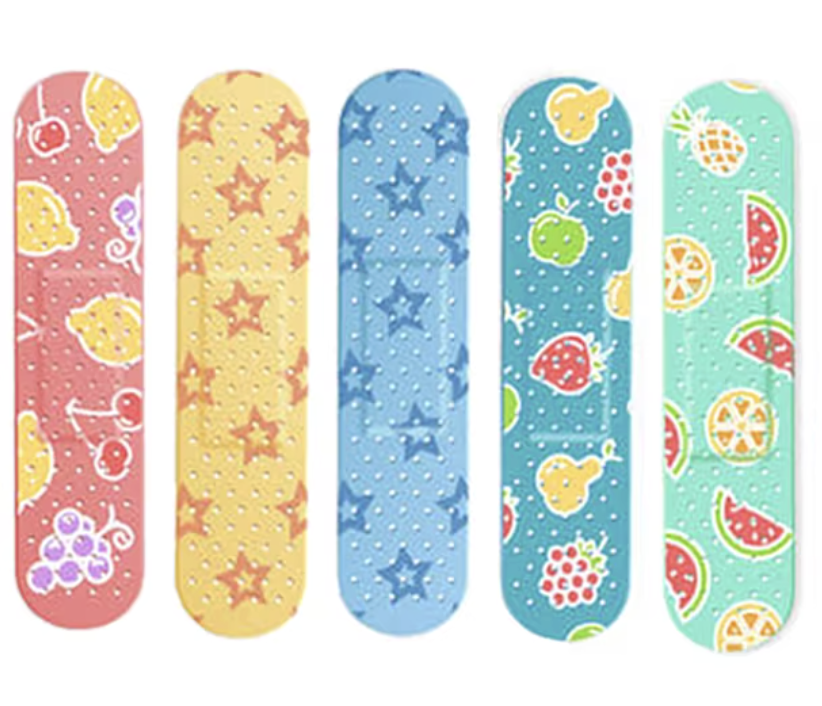

## Option 1 - The direct fix: just ask for a higher quota

It's the simplest, most legitimate path: API Gateway's account-level throttle is explicitly documented as adjustable on request through AWS Support - unlike some other hard-coded limits, this one genuinely can be raised for a known, legitimate traffic pattern. For a company running a scheduled, known-in-advance event (exactly what a ticket onsale is), this is the first, obvious lever - and it's almost certainly part of what real companies do before a major sale.

## Option 2 - No literal "API Gateway Load Balancer" product, but a real architectural swap
AWS's **Application Load Balancer** (ALB) has no comparable fixed request-rate ceiling at all - AWS doesn't publish a hard RPS quota for it the way it does for API Gateway, and it's documented as capable of handling well over 100,000 requests/sec, scaling toward millions with proper pre-warming. 

The architectural reason is real, not incidental: API Gateway operates deep at the application layer — parsing full HTTP semantics, running usage plans, request validation, API keys - and that richness has a throughput cost. ALB operates with far less of that per-request overhead, trading away API Gateway's built-in management features for raw throughput headroom.

So a genuine, real option for an extremely high-throughput API is to put ALB in front of Lambda instead of API Gateway - you lose some convenience (API Gateway's request validation, built-in throttling-as-a-feature, usage plans) but gain a front door with no comparable hard ceiling of its own.

## Option 3 - for truly planet-scale, shard across accounts/regions

Since API Gateway's quota is explicitly per account, per region, a real pattern at the largest scale is deploying the same API into multiple AWS accounts and/or regions, then fronting all of them with a genuinely global layer - [CloudFront](https://aws.amazon.com/cloudfront/), [AWS Global Accelerator](https://aws.amazon.com/global-accelerator/), or [Route 53 weighted/latency-based routing](https://docs.aws.amazon.com/Route53/latest/DeveloperGuide/routing-policy-latency.html) - that spreads traffic across them. Each account gets its own independent quota pool; the global layer decides which pool a given request lands in.

## But...*none of this actually solves Ticketmaster's real problem!*

Every option above is about *absorbing more raw volume*: a bigger pipe. 

But we already confirmed, with sworn Senate testimony, that Ticketmaster's actual failure wasn't "*our pipe was too narrow*" in a generic sense - it was that bots directly attacked the verification/admission layer itself. 

A bigger ALB, a higher API Gateway quota, more sharded accounts - none of that distinguishes a real fan from a bot hammering the same front door. 

That's precisely why the real fix in this space isn't "scale the pipe bigger," it's the **waiting room design** sitting at the CloudFront/edge layer, deciding *who gets admitted at all*, before any request ever reaches API Gateway, ALB, or any backend quota. 

The waiting room's entire value isn't that it has a higher ceiling than API Gateway - it's that it changes the question from "*can our pipe handle this volume*" to "*should this specific request even be allowed to try*". That's a different kind of defense than anything in options 1-3, and it's the one actually aimed at the problem Ticketmaster really had.

# Designing a real Waiting Room

<center>
<img src="ipynb.images/shanghai-hongqiao.png" width=1000/>
</center>
<br />

We can apply the same tools we learned in Week 5 to a genuinely different design pattern. 

Week 5's core design patterns are Publish-Subscribe (SNS $\rightarrow$ Observer) and Competing Consumers (SQS). 

A waiting room is a third, distinct pattern: admission control / gatekeeping via an <mark>atomic counter comparison</mark> (does that ring a bell?) - closer to a token bucket than to pub-sub or queue-competition. 

Lambda + DynamoDB + API Gateway aren't tied to one architectural idea. The same small toolkit recombines into fundamentally different capabilities depending on the problem.

Rather than having your AI whisper implementations to your ear, i'll give some options.

## Some options
- Using  Redis/ElastiCache specifically for its atomic counters at true production scale
- DynamoDB's own atomic increment (`UpdateExpression="SET counter = counter + :incr"`)

# The DynamoDB design (Design "A")
Here's hwo Gemini might do it, with six small pieces:
- `WaitingRoomTable` (DynamoDB) - one row per visitor: `visitor_id`, `queue_position`
- `AdmittedCountersTable` (DynamoDB) - a single row holding two atomic counters: `next_queue_position` and `serving_counter`
- `JoinQueue` Lambda (`POST /waiting-room/join`) - atomically increments `next_queue_position`, assigns it to the visitor, returns their position
- `CheckStatus` Lambda (`GET /waiting-room/status/{visitor_id}`) - compares the visitor's position against the current serving_counter; admits them if their turn has come
- `AdvanceServingCounter` Lambda - triggered on a schedule ([AWS EventBridge](https://aws.amazon.com/eventbridge/)) — advances `serving_counter` by a configurable admission rate. This one knob is the entire mechanism - it's what decides how fast the real backend gets fed, completely independent of how fast the front door fills up.
- A small, one-line gate added to `OrderProducer` - check `admitted=true` before doing any real work, reject otherwise

But your AI may have another idea. It may even be better. As long as it works, it's cheap, and it's robust, that works for me!

Joining the waiting room costs almost nothing — one DynamoDB atomic increment, no SNS, no fan-out, no Kinesis. You can throw a large, dramatic burst at `/waiting-room/join` for pennies, while the expensive part (real orders triggering the full fan-out pipeline) only ever happens at whatever throttled rate configured. 

# SQS design (Design "B")
## What a waiting room fundamentally needs that SQS's API simply doesn't expose

The defining customer-facing feature of a real waiting room - "*you are #4,392,105 in line*" - is a **rank query**: given a specific person, where do they currently stand relative to everyone else? 

SQS's API has no concept of this at all. You cannot ask SQS "*what position is message X currently at in the queue*" - messages are consumed from the front, full stop, with zero visibility into rank for anyone outside that consumption process. 

If a visitor's "ticket" were an SQS message, there's no way for them to repeatedly poll "am I close yet?" without an entirely separate mechanism tracking that information anyway - at which point we need a database regardless, just bolted awkwardly onto a queue that isn't actually doing the position-tracking work.

This isn't a stylistic preference - it's confirmed by what the real systems actually do: the AWS reference architecture we researched earlier uses exactly this counter-comparison design (`queue_position` vs. `serving_counter`), not a queue, for precisely this reason.

## Throttling the admission rate

If our actual goal is narrower than full position-visibility — just "*throttle the admission rate into the backend, no customer-facing wait display required*" - then an SQS-based admission queue is simpler and better, not just an acceptable alternative. 

Visitors' join requests drop into a queue; a rate-limited consumer (fixed reserved concurrency) drains it at a controlled pace; whatever gets dequeued is what gets admitted. No atomic counter contention, no blocking, genuinely idiomatic SQS usage. You lose "*here's your position*", but the backend only ever sees the throttled rate, regardless of front-door burst size.

So we have two options so far:

**Option A** - full position-visible waiting room (DynamoDB counters).

**Option B** - simplified SQS-based admission-rate-limiter, no position visibility, simpler and more idiomatic.

And now:

# Design "C": Redis/Elasticache

## The VPC requirement

ElastiCache nodes are not publicly reachable - they live inside a VPC, period, for both node-based clusters and standard Serverless. 

But... there is one genuine exception: [ElastiCache Serverless on Valkey 9.0+ can expose a public endpoint secured by IAM auth and TLS - which, if it holds up in practice, would let Lambda connect without VPC placement at all](https://docs.aws.amazon.com/AmazonElastiCache/latest/dg/serverless-public-endpoints-chapter.html). 

## The cost model

This is a fundamentally different cost shape than anything else so far:

- Serverless Valkey: ~`$6.13`/month minimum floor - billed continuously, regardless of whether a single request ever hits it
- Serverless Redis OSS: ~`$91.25`/month minimum floor - dramatically higher, because of a 1GB metered-storage minimum vs. Valkey's 100MB.
- Node-based (cache.t4g.micro): ~`$0.017`/hour ≈ `$12.41`/month - a flat hourly charge that ignores command volume entirely. Whether the cache handles 10 requests or 10 million, the bill is identical.

How long the stack stays deployed matters more than how much load we generate. Every other resource we've built so far, Lambda, DynamoDB on-demand, SQS, SNS, even Kinesis at $0.015/shard-hour - has been close enough to free at rest that destroy-discipline was good practice, not a financial necessity. 

<mark>ElastiCache is the first one where forgetting to tear it down overnight genuinely costs real, continuously-accruing money, independent of whether we ever actually ran the homework's test traffic</mark>. That's why I asked you to be careful to `cdk destroy` Week 6.

For a brief, deliberate test - deploy, run the comparison, destroy within hours - either option genuinely fits "a few dollars" (Valkey Serverless's `$6.13`/month floor prorates to roughly `$0.20`/day). 

But it breaks the risk-free character every prior assignment has had, where one of you forgetting to destroy overnight cost essentially nothing.

Week 6 teaches ElastiCache as a read-through cache (the textbook "when to cache" use case: reduce database read load). The waiting room now gives us a second, structurally different reason to reach for Redis: not caching data, but exploiting its atomic-increment speed for a high-contention counter. 

That's a meaningfully broader understanding of what the tool is actually for — "Redis isn't just a cache, it's also the right tool when you need extremely fast atomic coordination" - which is a real, valuable generalization most caching-focused curricula never get to.

The six-component architecture (`WaitingRoomTable`-equivalent, counters, `JoinQueue`, `CheckStatus`, `AdvanceServingCounter`, the gate in `OrderProducer`) stays the same shape - only the counter storage changes from DynamoDB to Redis.

The hot-partition limitation maps directly onto a comparison exercise now: Why Redis's `INCR` sustains dramatically higher throughput than a single DynamoDB item under the same contention.

## A VPC Issue associated with this design
The recurring cost/complexity tax every VPC-based week has specifically called out are **NAT Gateways**.

`OrderProducer` already reaches DynamoDB and SNS - both public AWS service endpoints, no VPC needed today. If we naively bolt the Redis admission-check directly into `OrderProducer`, `OrderProducer` itself would need to move into the VPC to reach Redis (which is VPC-only), while also retaining its existing access to DynamoDB and SNS. 

That combination -private-only resource plus public-service access, from the same function- is exactly the situation that forces a NAT Gateway (or VPC endpoints) into the picture, the same cost that makes Weeks 6, 7, and 11 meaningfully more expensive and complex than Weeks 1, 2, and 5.

But there is a fix: *isolate the VPC boundary to only the functions that truly need it*!

So, don't put `OrderProducer` in the VPC at all. Instead:

`JoinQueue`, `CheckStatus`, and `AdvanceServingCounter` - these three live in the VPC, because their only job is talking to Redis. Since they need nothing else (no DynamoDB, no SNS, no public internet), they need no NAT Gateway and no VPC endpoints at all - a private subnet with just a route to the Redis cluster is sufficient.

`OrderProducer` stays exactly where it is today - *outside* the VPC, untouched, with all its existing logic intact. It gains exactly one new step: a plain HTTPS call to `CheckStatus`'s own API Gateway endpoint (public, like any other API Gateway route) to ask "*is this visitor admitted?*" before doing its real work.

This works because calling into a VPC-resident Lambda from outside the VPC is completely normal - it's just an ordinary API Gateway $\rightarrow$ Lambda invocation, no different from any other request we've built. The constraint is only ever about a function reaching into the VPC from the compute side; it was never about who's allowed to call it from outside.

This isolates VPC complexity to exactly the three small, single-purpose functions that genuinely require it, while every piece of infrastructure (`OrderProducer`, the fan-out, all three consumers) remains completely unchanged.

That's also a nice boundary: it reinforces proper service decomposition (a function's own network placement should be driven by what it actually needs to reach, not by what some other part of the system happens to need) rather than mushing VPC and non-VPC concerns into one Lambda.

So... Option C is genuinely tenable. 

## Pricing
The VPC itself costs $0 extra - if, and only if, these three functions need nothing but Redis

A NAT Gateway is only required when something inside a VPC needs to reach something outside it (the public internet, or a public AWS service endpoint like SNS). If `JoinQueue`, `CheckStatus`, and `AdvanceServingCounter` talk to Redis and nothing else - no DynamoDB, no SNS, no internet - then a private subnet with a security group permitting traffic to the ElastiCache cluster is completely sufficient. No NAT Gateway, no VPC endpoints, no additional networking cost of any kind. The VPC's existence, by itself, is free.

## What we'd have paid if the design weren't scoped this carefully

A NAT Gateway costs ~`$32.40`-`32.85`/month per gateway, per Availability Zone - meaning a standard multi-AZ setup runs `$65-98`/month just for the gateway to exist, before a single byte flows through it - plus `$0.045`/GB processed, plus standard AWS egress charges on top if that traffic leaves AWS entirely. 

This is a genuinely large, widely-documented cost trap. Avoiding it entirely, just by keeping `OrderProducer` outside the VPC and giving the Redis-only functions no other dependencies, is a real, concrete architectural win. This is what correct service-boundary design saves you, not just an incidental detail!

That is why your repo has a `cost_guard.py` in your `scripts` folder. It catches too expensive deployments at the level of your `cdk synth`, so that you can rethink your designs *and tell your AI it is too *high-maintenance* for you🤭).

## The one caveat, and the fix

If these functions did also need DynamoDB for some reason (say, keeping a separate visitor-history table), you still wouldn't need a NAT Gateway for that specifically - DynamoDB (and S3) uniquely support Gateway VPC Endpoints, genuinely $0/hour and $0/GB - a free, direct private route from inside the VPC to that one service. 

Only other AWS services (SNS, SQS, etc.) would need the cheaper-but-still-nonzero Interface Endpoints (~`$0.01`/hour + `$0.01`/GB) - and in this design, nothing requires that at all.

## So, the real comparison between Option B and Option C

The networking is a wash - `$0` either way, given correct scoping. The actual, entire cost gap between the two options is just:

- Option B (SQS): effectively free - pay-per-request pennies, zero cost at rest
- Option C (Redis/ElastiCache): the `$6.13`-`$91.25`/month minimum floor, billed continuously regardless of usage

That's the real, isolated tradeoff - not VPC complexity, not NAT Gateway tax, just ElastiCache's own existence cost versus SQS's near-zero one. 

The "Redis costs more" story is entirely about the cache itself, once the surrounding architecture is designed properly - which is itself a good, concrete lesson in why where you draw service boundaries matters as much as which tool you pick.

# Comparing Options A, B, C
Let's compute this precisely, using the exact DynamoDB pricing this course has relied on all term, and then put all three options side by side for a clean final comparison.

**Option A** costs about `$0.53` for a full 60,000-visitor test run - assuming each visitor polls `CheckStatus` roughly 10 times while waiting, plus one join write and one final admit-flip. Genuinely in the same cost universe as everything else we've built together: pure pay-per-request, zero cost at rest, no VPC at all (DynamoDB is a public, fully serverless AWS service, same as every other resource we've used except RDS and ElastiCache).


|	|Cost at 60,000-visitor test	|Cost sitting idle overnight	|VPC required?|	Fidelity to the real pattern|
|----|--------|---------|------|-------|
|A - DynamoDB counter|	~`$0.53`|	`$0`|	No|	Approximation — real systems avoid this exact design due to hot-partition contention|
|B - SQS admission queue|	~`$0.01-0.05`|	`$0`|	No|	Simpler lesson — throttles admission rate, but no customer-facing queue position|
|C - Redis/ElastiCache|	ElastiCache's cost is flat regardless of visitor count (confirmed earlier — billed by node-hour or storage floor, not request volume)|	`$6.13` - `$91.25`+|	Yes (though `$0` extra if scoped correctly)|	Matches the real, published AWS/SeatGeek reference architecture exactly|

Option A and B are the only two where you forgetting to tear the stack down costs nothing - consistent with the zero-risk character of literally every assignment we've built before this one. 

Option C is the only one where idle time itself is the dominant cost, independent of whether the assignment's test traffic ever runs at all.

Option A is a baseline (cheap, risk-free, and its own hot-partition ceiling becomes a legitimate "find the bottleneck" discovery exercise).

Option C offered is an explicit stretch goal for after Week 6 (?), when VPC fluency already exists and the real financial stakes of forgetting to destroy are something you can be trusted to manage deliberately.

## Picking Options
I am going to let you design the option you want. You only need to implement one option from the three listed.

However, each option comes with its own coefficient of difficulty, just like in springboard diving:

<center>
<img src="ipynb.images/sd-springboard-diving.jpg" width=300 />
</center>

- Option B (easiest): 1.0
- Option A (medium): 1.04
- Option C (hardest): 1.08

So if a project gets 89 points out of 100 and implements Option C, the grade is $89 \times 1.08 = 96$. Of course, the more complex the option, the higher the chances you make mistakes and points come off.

# How we're going to simulate a Taylor Swift level stampede for concert tickets

We're going to use a "cap" to model a backend with *limited capacity*, which is one limit we chose and set at <mark>40 requests a second (with a burst allowance of 100)</mark>. 

An uncapped load, as you know from your 100 req/sec load test on Week 5, took our crowd with zero errors. At Ticketmaster scale it would fail somewhere. But we cannot simulate that with our AWS cdk and we don't want to pay for 14 million users, either. Since
our system's capacity is unknown, so in order to simulate the Ticketmaster incident, we're going to set a cap at 40 req/ sec. What carries over is the ratio of demand to capacity. If 100 new visitors a second hit a cap of 40, which is 2.5 times capacity, 41% will be turned away.

|	|Our stampede|	Taylor Swift presale, Nov 15 2022|
|---|------------|-----------------------------------|
|People|	1,520 virtual visitors|	14 million people hit the site, including bots, and 1.5 million were invited to buy|
|Pressure|	peak arrivals 2.5x the cap|	3.5 billion system requests, 4x Ticketmaster's previous peak|
|Bots|	5% of the crowd (about 76)|	blamed for a staggering number of bot attacks, with no share given|
|Duration|	25 seconds|	hours|

The 2.5x and the 4x aren't directly comparable. Ours is demand against a cap, theirs is demand against their previous peak.

Each of our 1,520 virtual fans stands for roughly 9,200 of the 14 million people who hit the site (14,000,000 ÷ 1,520). Our cap stands for whatever the real backend can take. Our test is a gentle version of the real event, but it shows the same mechanism: when demand exceeds capacity, either some people get errors, as with the cap, or everyone waits in an orderly line, as with a waiting room.

If you run the designed load test with the cap at 40 and not waiting room, you will get `429` errors that represent fans being rejected. Your job is to design a waiting room so that *no fans are ever rejected*, by implementing either option A, option B, or option C.

The repo and utilities is designed so you can only design the waiting room and not change the underlying framework.
 
Here's the midterm contract, and the repo you need to work with. There are a lot of tools I designed for you, such as a pre-deploy cost guard to make sure to know the cost of your deployment before you deploy. Read the section below

# The Contract

Teams of two. 24 hours. AI assistants are allowed (section 8).

| | |
|---|---|
| Released | [DATE AND TIME] |
| Due | [24 HOURS LATER] |
| Hand in to | [WHERE] |

## 1. The scenario

Tickets for a famous tour go on sale. A few fans trickle in before the doors open. Then about 1,500 people arrive
within 15 seconds, and about 5 in every 100 of them are bots that skip the line and go straight for the order button.

You have the Week 5 event-driven order system. It accepts every order the instant it arrives. A real backend cannot
do that, so in this exam the order endpoint is limited to **40 requests per second** (with a burst allowance of 100).
Send the whole crowd straight at it and about four in ten fans get an error. Nobody is served fairly, and the bots
do well.

Your job is to put a **virtual waiting room** in front of `POST /orders`:

- every fan joins a line and can ask where they stand;
- fans are let through at a steady rate the backend can take;
- bots without a place in line are turned away;
- the order endpoint never receives more than it can handle; and
- **every fan is served.**

## 2. Choose one option

Each team builds exactly one option. The three designs were discussed above. The implementation is yours.

| Option | Design | Difficulty coefficient |
|---|---|---|
| **B** | An SQS admission queue, drained at a controlled rate | 1.0 |
| **A** | A DynamoDB waiting room (an atomic counter) | 1.04 |
| **C** | A Redis (ElastiCache) INCR counter | 1.08 |

Your grade is the **difficulty coefficient times your execution score** (section 6). A harder option is worth more
only if it works.

## 3. What you receive and what you write

**Provided. Do not modify these files:**

- the Week 5 baseline system: the API, `OrderProducer`, the three consumers and their tables;
- the **gate**, built into `OrderProducer`: every order must present a valid admission, which the gate verifies and
  consumes;
- the load tests in `load-test/`;
- the tools in `scripts/` (table below);
- a one-page dashboard with the shared panels and a slot for your option-specific widgets;
- a skeleton that shows where your option plugs in.

**You write:**

- your option's logic and infrastructure;
- your own tests, including the cases where several things happen at the same time;
- the three standard telemetry calls (one line each, from the provided `telemetry.py`) and your option-specific
  dashboard widgets;
- a short written explanation (section 7).

The starter's `README.md` says exactly where each piece goes, and `RUBRIC.md` says what each grading component looks
like at full credit.

| Tool | When you run it |
|---|---|
| `artillery run -e stampede load-test/stampede-direct.yml` | Step 0: the same crowd with no waiting room, so you see the problem |
| `cost_guard.py` | before every deploy; it must say OK |
| `seed_stampede_inventory.py` | after every fresh deploy |
| `contract_check.py` | after the deploy and before any load test; it must PASS |
| `artillery run -e rehearsal ...` | a small trial of about 150 visitors; always do this first |
| `artillery run -e stampede ...` | the real test, about 1,500 visitors, with `--output yourfile.json` |
| `check_run.py` | on your stampede file; it prints the scorecard |
| `summarize_stampede.py` | on the same file; it prints what the backend saw every 10 seconds |
| `verify_kit.py` | before you hand in; it shows you did not change a provided file |

## 4. The HTTP contract

Your waiting room must answer exactly like this. The load test and the probe depend on it.

```
POST /waiting-room/join
  -> 202  {"visitor_id": "<uuid>", "status": "waiting",
           "poll_interval_seconds": <number>, "poll_path": "/waiting-room/status/<uuid>"}

GET /waiting-room/status/{visitor_id}
  -> 200  {"status": "waiting"}
  -> 200  {"status": "admitted", "admission_token": "<token>", "expires_at": <epoch seconds>}
  -> 200  {"status": "admitted", "order_placed": true}     (after the order; the token is no longer shown)
  -> 400  the visitor_id is malformed

POST /orders   with the headers   X-Visitor-Id: <uuid>    X-Admission-Token: <token>
  -> 201  accepted
  -> 403  not admitted: missing, wrong, expired or already used
  -> 503  the gate could not verify the admission (it fails closed)
```

Extra fields in a response are allowed (for example a position in line or an estimated wait). The load test ignores
them.

Rules your waiting room must keep:

- The line is first come, first served.
- A visitor who has only joined cannot order.
- An admission is **single use**: one admission buys one order. Until it is used, asking again returns the same token.
- An admission expires.

**The record the gate reads.** The provided gate checks every order against one DynamoDB record per admitted
visitor. Your option must write that record when it admits someone:

| Field | Type | Meaning |
|---|---|---|
| `visitor_id` | string, the table's key | the visitor |
| `admission_token` | string | the secret the visitor presents |
| `used` | boolean | `false` when written; the gate sets it to `true` |
| `expires_at` | number, epoch seconds | the gate refuses the token after this time |
| `ttl` | number, epoch seconds | when DynamoDB may delete the record |

The gate accepts an order only if the record exists, the token matches, `used` is still `false`, and `expires_at` is
in the future, and it marks the record used in one atomic step. Your admissions table must be the one the starter
hands to the gate.

## 5. The capacity rule and your admission rate

**See the problem first.** Before you build, deploy the starter with only `-c orders_rate_limit=40`, run
`artillery run -e stampede load-test/stampede-direct.yml --output baseline.json`, and score it with
`python3 scripts/check_run.py baseline.json --expect-failures 0.3`. Roughly four in ten requests are rejected with
HTTP 429 (Too Many Requests). That is the failure your waiting room exists to remove, and `baseline.json` is your
comparison for the rest of the exam.

**The cap.** Deploy with `-c waiting_room=on -c orders_rate_limit=40`, as the starter's README shows. `POST /orders` then accepts about
40 requests per second (burst 100) and answers anything beyond that with HTTP 429. **One 429 fails the scorecard.**

**The crowd.** The stampede load test sends about 1,520 visitors in 25 seconds: 10 seconds of early arrivals, then
15 seconds at 100 new visitors per second. About 95% are fans and about 5% are bots.

- A fan joins, then asks for its status about every 5 seconds (the interval varies by up to 20%) until admitted, then
  places one order.
- A fan gives up after 120 polls, about 10 minutes.
- A bot skips the line and goes straight to `POST /orders`.

**Your admission rate.** You choose how many visitors per second your waiting room admits. It must be:

- **low enough** that the order endpoint stays under the cap, with margin: the order requests that reach it come in
  bunches, not perfectly evenly; and
- **high enough** that the last fan is admitted long before giving up. For about 1,440 fans, anything under about 3
  per second makes some of them give up.

The reference solutions admit 10 per second.

Whatever you choose, **declare it** when you score your run: `python3 scripts/check_run.py yourfile.json
--configured-rate N`. The scorecard measures your steady admission rate over the middle of the run, and it must land
between 60% and 110% of the rate you declare.

## 6. How you are graded

**Hard gate.** Your submission must include a passing `contract_check.py` output. Without it, your performance
results are not graded.

**Execution score (out of 100):**

| Component | Points |
|---|---|
| **Correctness evidence:** the scorecard PASSES on your own stampede run | 30 |
| **Design and rationale:** your written explanation of what you built and why | 20 |
| **Tests:** your own tests of your option's logic, including simultaneous events | 15 |
| **Interpretation:** you explain your own numbers (rate, waits, peak load, and how they differ from your baseline) | 15 |
| **Deployment and cost:** a clean deploy, `cost_guard.py` OK, everything destroyed afterward | 10 |
| **Telemetry:** you emit the three standard metrics at the right moments, and your option-specific dashboard widgets are correct and readable | 10 |

Your final grade is the difficulty coefficient (B 1.0, A 1.04, C 1.08) times this score.

**What the scorecard checks.** Every bot is turned away. No order is accepted without an admission. At least 99.5% of
the fans who joined are admitted, and nobody gives up. Your measured rate is within 60% to 110% of the rate you
declare. There are no 429s and no 5xx. Failed virtual users and client-side errors stay below 0.5%.

**Exit codes.** `0` means every rule passed. `1` means a rule failed. `3` means **INVALID RUN**: the load generator lost
requests that your system never saw. An invalid run is not graded. Rerun it, from a steady network, on power.

## 7. What to hand in

1. Your repository (a zip or a link) with your option's code and your tests.
2. The output of `cost_guard.py` from before your final deploy.
3. The output of `contract_check.py`.
4. Your raw stampede file (the `.json` that `artillery` wrote), the output of `check_run.py` run on it with your
   declared `--configured-rate`, and the output of `summarize_stampede.py`. The instructor reruns the scorecard on your
   file. Include your baseline run too: `baseline.json`, the output of
   `check_run.py baseline.json --expect-failures 0.3`, and the output of `summarize_stampede.py baseline.json`.
5. The output of `verify_kit.py`.
6. A screenshot of the one-page dashboard during your stampede, showing your option-specific widgets.
7. A written explanation of at most two pages:
   - your design in a paragraph, and why you chose this option;
   - what limits your option: the first thing that would break if the crowd were ten times larger, and why;
   - your numbers: the rate you declared against the rate you measured, the wait times (median, 95th percentile,
     maximum), and the peak orders per second, each compared with your baseline; and an explanation of any gap between what you expected and what
     happened;
   - one thing you would change.
8. Confirmation that you destroyed your stack.

## 8. Rules of the road

- **Do not change provided files.** That includes the gate, the load tests (their timing and connection settings
  too), and the tools. `verify_kit.py` detects changes. Do not raise or remove the cap, and do not bypass the gate.
- **AI assistants are allowed.** You must understand and be able to explain everything you hand in. The written
  explanation and your answers about your own numbers are graded, and they cannot be borrowed. Copying another team's
  work is academic misconduct, and so is editing a run file.
- **Budget.** The whole exam should cost less than `$2` of AWS usage. Sending traffic costs cents; resources that stay
  running cost money. Run `cost_guard.py` before every deploy, set an AWS Budgets alert at $2, and destroy your stack
  when you finish.
- **Before you start,** check your Lambda concurrency quota:
  `aws lambda get-account-settings --query 'AccountLimit.ConcurrentExecutions'`. If it is below 100, tell the
  instructor first: a low quota makes a correct solution look broken.
- **Test small first.** Run `-e rehearsal` before `-e stampede`, and run the stampede only after `contract_check.py`
  passes.
- **Running the stampede.** Use a steady network, keep the machine awake and on power, and do not use a VPN.
- **Plan your time.** Some designs create networking or caches, and a deploy of those can take about ten minutes per
  attempt. A failed deploy costs more.
- **One stack at a time.** Do not leave an old stack running while you test a new one.


# The repo

Read `CONTRACT.md` first. It is the assignment. This file explains how to work in this repository.
`RUBRIC.md` says what each grading component looks like at full credit.

## What is in the box

| Path | What it is | Yours to change? |
|---|---|---|
| `cdk/waiting_room.py` | the skeleton of your waiting room | **yes** |
| `lambdas/waiting_room/` | your Lambda code; the two handlers return 501 until you write them | **yes**, except `telemetry.py` |
| `tests/` | your tests; `test_starter_wiring.py` checks the plumbing | **yes**, add yours |
| `cdk/stack.py`, `cdk/app.py` | the baseline stack and its wiring to your construct | no |
| `lambdas/order_producer/` | the order endpoint and the **gate** | no |
| `lambdas/*_consumer/` | the three baseline consumers | no |
| `lambdas/waiting_room/telemetry.py` | the metrics helper | no |
| `load-test/` | the load tests | no |
| `scripts/` | the tools | no |
| `kit_manifest.json` | checksums of every file marked "no" | no |

`python3 scripts/verify_kit.py` tells you whether you changed a provided file. Run it now, once, to see a PASS.

## One-time setup

```bash
python3 -m venv .venv && source .venv/bin/activate
pip install -r cdk/requirements.txt -r requirements-dev.txt
npm install -g artillery                     # if you do not have it
export AWS_DEFAULT_REGION=us-east-1
unset INVENTORY_TABLE                        # a leftover from another week can point the seed script at the wrong table
```

## Step 0: see the problem (about 15 minutes)

Before you build anything, run the same crowd with no waiting room, so you see what you are fixing. Deploy with ONLY
the cap, run the direct stampede, and score it (set `API_ENDPOINT` exactly as in step 4 below):

```bash
(cd cdk && cdk deploy -c orders_rate_limit=40)
python3 scripts/seed_stampede_inventory.py
artillery run -e stampede load-test/stampede-direct.yml --output baseline.json
python3 scripts/check_run.py baseline.json --expect-failures 0.3
python3 scripts/summarize_stampede.py baseline.json
```

Roughly four in ten requests are rejected with HTTP 429 (Too Many Requests): the order endpoint's limit. Keep
`baseline.json`. You hand it in, and you compare your waiting room's run against it. You do not need to destroy the
stack before step 3: deploy again with `-c waiting_room=on` and your waiting room is added.

## The working loop

1. Write your construct (`cdk/waiting_room.py`) and your handlers (`lambdas/waiting_room/`).
2. Test without AWS: `pytest` from the repository root.
3. Check the cost, then deploy:

   ```bash
   (cd cdk && cdk synth -c waiting_room=on -c orders_rate_limit=40 > /dev/null) && python3 scripts/cost_guard.py
   (cd cdk && cdk deploy -c waiting_room=on -c orders_rate_limit=40)
   ```

   Your admission rate defaults to 10 per second; change it with `-c admit_per_second=N`.
4. Seed the inventory, probe the contract, then run the load tests:

   ```bash
   export API_ENDPOINT=$(aws cloudformation describe-stacks --stack-name Week5EventDrivenStack \
     --query "Stacks[0].Outputs[?OutputKey=='ApiEndpoint'].OutputValue" --output text | sed 's:/*$::')
   python3 scripts/seed_stampede_inventory.py
   python3 scripts/contract_check.py                       # must PASS before any load test
   artillery run -e rehearsal load-test/stampede-waiting-room.yml
   artillery run -e stampede  load-test/stampede-waiting-room.yml --output mine.json
   python3 scripts/check_run.py mine.json --configured-rate 10     # declare YOUR rate
   python3 scripts/summarize_stampede.py mine.json
   ```
5. Before you hand in: `python3 scripts/verify_kit.py`
6. When you finish: `(cd cdk && cdk destroy --force)`

## Testing your handlers

Your handlers create their AWS clients when they are imported, so each test starts a mock and then imports the
handler fresh. `tests/conftest.py` does the plumbing:

```python
from conftest import load_module

def test_join_answers_202(aws):                       # `aws` is a fresh mocked AWS
    join = load_module("waiting_room/join_handler.py")
    response = join.lambda_handler({}, None)
    assert response["statusCode"] == 202
```

Add anything else your option needs (a queue, an environment variable) to the `aws` fixture. A test that cannot fail
is worth nothing: check that yours fail when you break the logic.

## Telemetry and the dashboard

Call the provided helper in your handlers, once per visitor:

```python
import telemetry
telemetry.joined()                  # when they get a place in line
telemetry.admitted()                # when their admission record is written
telemetry.time_in_line(seconds)     # at admission: seconds since they joined
```

The deploy creates a dashboard named **Info7375-Week5-Midterm** with twelve common panels, three of them drawn from
those metrics. <mark>Add up to three widgets of your own by returning them from `WaitingRoom.dashboard_widgets()`, and add
every Lambda you create to `self.functions` so the errors panel counts it</mark>. Metrics take about a minute to appear.

## If something looks wrong

| What you see | What it means |
|---|---|
| `403` with `{"message":"Missing Authentication Token"}` on `/waiting-room/join` or `/waiting-room/status/...` | That route is not deployed: you deployed without `-c waiting_room=on` (Step 0 deploys the baseline on purpose). Deploy again with `-c waiting_room=on -c orders_rate_limit=40`. This is not a problem with tokens or with the gate. |
| `501` with `not_implemented` | The route is deployed and is answering with the starter's stub: you have not written that handler yet. |
| `403` with `admission_required` or `invalid_admission` on `POST /orders` | The provided gate turned the order away: no admission, a wrong or already used token, or an expired one. The gate is doing its job. |
| `503` from `POST /orders` | The gate could not check the admission and failed closed. Check that your admissions table is the one `cdk/waiting_room.py` hands to the stack, and that your handler writes the record described in `CONTRACT.md`, section 4. |

## Rules in one place

Do not change a provided file, do not add files inside `scripts/`, `load-test/` or the provided `lambdas/` folders, and
do not raise or remove the cap. `verify_kit.py` detects all three. Put your own files in `cdk/`, `lambdas/waiting_room/`
and `tests/`.


# Nota Bene
This notebook is a commented introduction to your midterm.

The official rules are in the provided repo.

To verify the provided repo, run this once in your own copy:

```bash
python3 scripts/verify_kit.py --expect-digest a6dc145562f452b5b8a12dfa7a8a88831f00a983994276fa65e649bc0d0a7ce6
```
If it says `RESULT: PASS`, you're set.

We'll work with whatever your lambda concurrency quota is, so please list it in your manifest.

Good luck😎

# TA Hours
Your TAs are going to schedule working hours for you this afternoon, this evening, and tomorrow morning. We worked on the midterm together so they know what works. Consult with them for help. And no, they are not going to give you solutions🫢, but they are going to help you overcome potential obstacles.

# Appendix: Some errors you may hit and how to fix them
## Lambda concurrency quota

My account quota says 1000 concurrent executions account-wide, the standard AWS default. That's a real, usable number for planning our load burst. Unfortunately, the TAs and you tell me that your account quota may be a lot lower. That is a problem. But we'll work with that. As a result of that, you may experience more errors, but you can still work on the designs and we'll take your quota in consideration.

Also keep in mind the polling interval is yours to tune. The predesigned load test in your repo takes `poll_interval_seconds` from the join response, so a longer interval, or a longer one for people far back in the line, cuts status traffic. One of your TAs with a lambda concurrency quota of 10 saw `5xx` drop from 6,723 to 1,147 going from 5-second to 10-second polling. That helps but won't entirely fix a quota of 10, and joins at 100 per second still fill most of it by themselves*.

## `cdk synth` fails with a CDK CLI older than 22 October
The error is `Cloud assembly schema version mismatch ...` You need at least CLI version
2.1146.1, and nothing deploys. cdk/requirements.txt asks for aws-cdk-lib>=2.130.0, so pip installs
2.274.0 (released 20 October), which needs CDK CLI 2.1146.1 (released 22 October). My CLI was
2.1136.0. Version 2.273.0 of the library still works with the older CLI. Updating the CLI with npm install -g
aws-cdk@latest fixed it.

## `contract_check.py` cannot connect on Macs with Python from python.org
The first request fails with SSL: CERTIFICATE_VERIFY_FAILED, so no check runs and the hard gate cannot
pass. The probe uses only the standard library, and the python.org installer for macOS has no certificate
store until its "Install Certificates" step is run. The other tools use boto3, which brings its own certificates, so
they kept working. Setting SSL_CERT_`FILE=$(python3 -m certifi)` got the probe working.